In [1]:
import pandas as pd
import os
import numpy as np
from matplotlib import pyplot as plt
import torch
from torch import nn
import tensorflow as tf

In [2]:
Npontos = 60 #Tempo de dados 60
features = 6

In [3]:
dataset = pd.read_csv('completo.csv')

In [4]:
parc_data_train = 0.8
andando = dataset.loc[dataset['atividade'] == 0]
split = int(len(andando)*parc_data_train)
train_andando = andando[:split]
teste_andando = andando[split:]


In [5]:
sentado = dataset.loc[dataset['atividade'] == 3]
split = int(len(sentado)*parc_data_train)
train_sentado = sentado[:split]
teste_sentado = sentado[split:]


In [6]:
escreve = dataset.loc[dataset['atividade'] == 15]
split = int(len(escreve)*parc_data_train)
train_escreve = escreve[:split]
teste_escreve = escreve[split:]

In [7]:
escada = dataset.loc[dataset['atividade'] == 2]
split = int(len(escada)*parc_data_train)
train_escada = escada[:split]
teste_escada = escada[split:]
treino = pd.concat([train_andando, train_sentado, train_escreve, train_escada])
teste = pd.concat([teste_andando, teste_sentado, teste_escreve, teste_escada])
treino = treino.replace({2: 1, 3: 2, 15:3})
teste = teste.replace({2: 1, 3: 2, 15:3})

In [8]:
label_teste = teste['atividade']
label_teste = label_teste.values
teste = teste[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']].values

In [9]:
label = treino['atividade']
treino = treino[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']].values
label = label.values

In [10]:
def cria_IN_OUT(data, janela, features):
    OUT_indices = np.arange(janela, len(data), janela)
    OUT = data[OUT_indices]
    IN = data[range(janela*len(OUT))]
    IN = np.reshape(IN, (len(OUT), janela, features))
    IN_final = IN[:,:,:]
    return IN_final
trainX = cria_IN_OUT(treino, Npontos, 6)
trainY = cria_IN_OUT(label, Npontos, 1)
testX = cria_IN_OUT(teste, Npontos, 6)
testY = cria_IN_OUT(label_teste, Npontos, 1)


In [11]:
media = np.mean(testX, axis=0)
desvio_padrao = np.std(testX)
testXn = (testX - media) / desvio_padrao
media = np.mean(trainX, axis=0)
desvio_padrao = np.std(trainX)
trainXn = (trainX - media) / desvio_padrao

In [12]:
testY = testY.astype(int)
testY.dtype
trainY = trainY.astype(int)

In [25]:
#teste de Label
for i in range(0,257,1):
    teste = False
    for x in range(0,58,1):
        if teste == False:
            teste = trainY[i][x][0]
        else:
            if teste != trainY[i][x][0]:
                print('errado')
print(trainXn[0][1])
print(trainX[0][1])

[-0.01852131  0.86642802  0.8763117   0.08673388 -0.13810259 -0.01077467]
[ 3.25372    -0.19183542  6.107758    0.3873821  -0.61854124 -0.0489718 ]


In [14]:
def cria_LSTM(hidden_units, dense_units, input_shape, activation):
  model = tf.keras.Sequential()
  model.add(tf.keras.layers.LSTM(hidden_units, input_shape=input_shape,activation=activation[0], return_sequences=True))
  model.add(tf.keras.layers.Dense(units=64, activation=activation[0]))
  model.add(tf.keras.layers.Dropout(rate=0.3))
  model.add(tf.keras.layers.Dense(units=32, activation=activation[0]))
  model.add(tf.keras.layers.Dense(units=dense_units, activation=activation[1]))
  model.compile(loss='sparse_categorical_crossentropy', optimizer ='adam', metrics=['accuracy'])
  return model

In [27]:

model = cria_LSTM(hidden_units=120, dense_units=4, input_shape=(Npontos, features), activation=['relu', 'softmax'])
resultado = []
for i in range(20):
    model.reset_states()
    history = model.fit(trainXn, trainY, epochs = 50, batch_size = 30, verbose = 1,  validation_data=(testXn, testY))
    resultado.append(history)


Epoch 1/50
336/336 [==============================] - 10s 24ms/step - loss: 5034.0215 - accuracy: 0.5607 - val_loss: 3.7256 - val_accuracy: 0.6026
Epoch 2/50
336/336 [==============================] - 8s 25ms/step - loss: 1.5688 - accuracy: 0.5778 - val_loss: 3.5855 - val_accuracy: 0.6264
Epoch 3/50
336/336 [==============================] - 9s 26ms/step - loss: 1.0156 - accuracy: 0.5935 - val_loss: 1.3088 - val_accuracy: 0.6258
Epoch 4/50
336/336 [==============================] - 9s 27ms/step - loss: 25.8872 - accuracy: 0.5888 - val_loss: 0.8545 - val_accuracy: 0.6251
Epoch 5/50
336/336 [==============================] - 9s 26ms/step - loss: 0.8391 - accuracy: 0.5998 - val_loss: 0.8163 - val_accuracy: 0.6179
Epoch 6/50
336/336 [==============================] - 8s 24ms/step - loss: 0.7928 - accuracy: 0.6167 - val_loss: 0.7784 - val_accuracy: 0.6384
Epoch 7/50
336/336 [==============================] - 8s 24ms/step - loss: 0.7641 - accuracy: 0.6268 - val_loss: 0.7609 - val_accuracy: 0

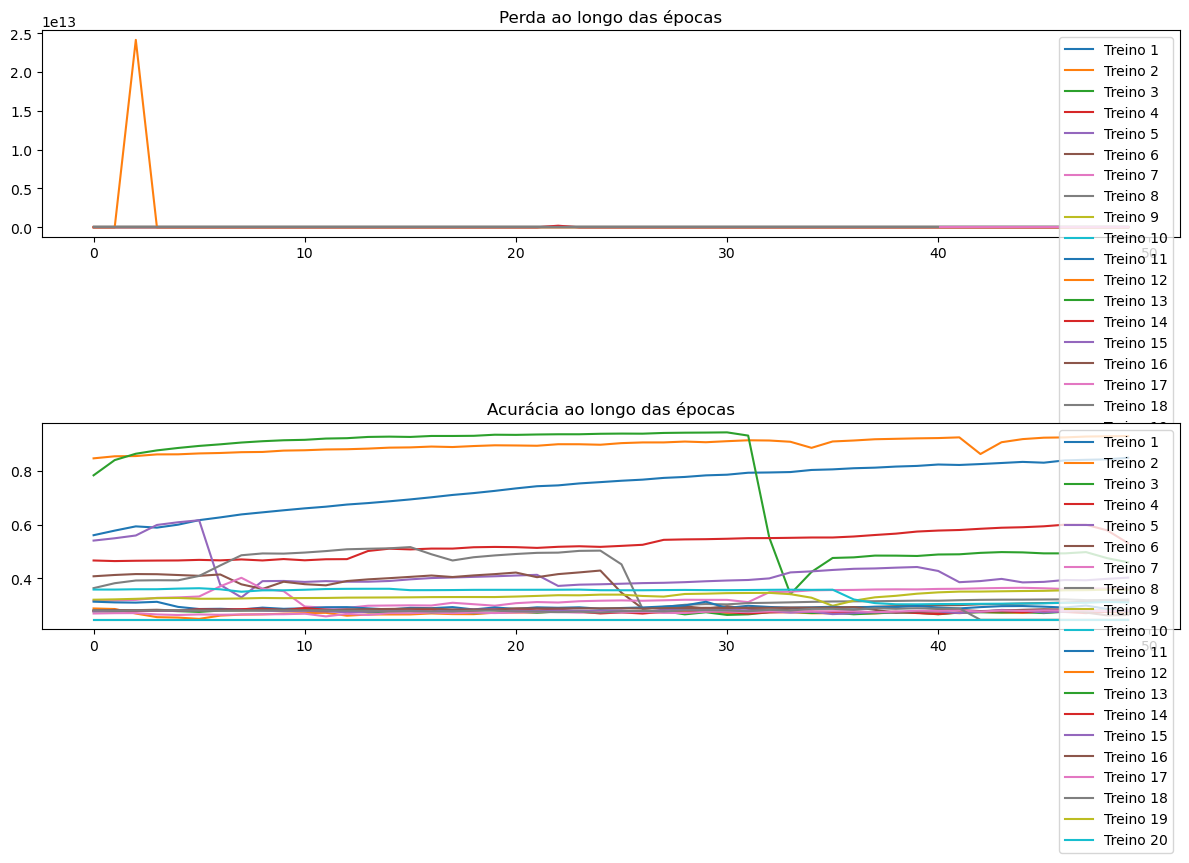

In [28]:
import matplotlib.pyplot as plt

# Seu código para criar o modelo e treinar

# Criar subplots
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8))

# Plotar a perda (loss) nos subplots[0]
axes[0].set_title('Perda ao longo das épocas')
for i in range(20):
    axes[0].plot(resultado[i].history['loss'], label=f'Treino {i + 1}')

# Plotar a acurácia nos subplots[1]
axes[1].set_title('Acurácia ao longo das épocas')
for i in range(20):
    axes[1].plot(resultado[i].history['accuracy'], label=f'Treino {i + 1}')

# Adicionar legendas
axes[0].legend()
axes[1].legend()

# Ajustar layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

Text(0.5, 0, 'epoch')

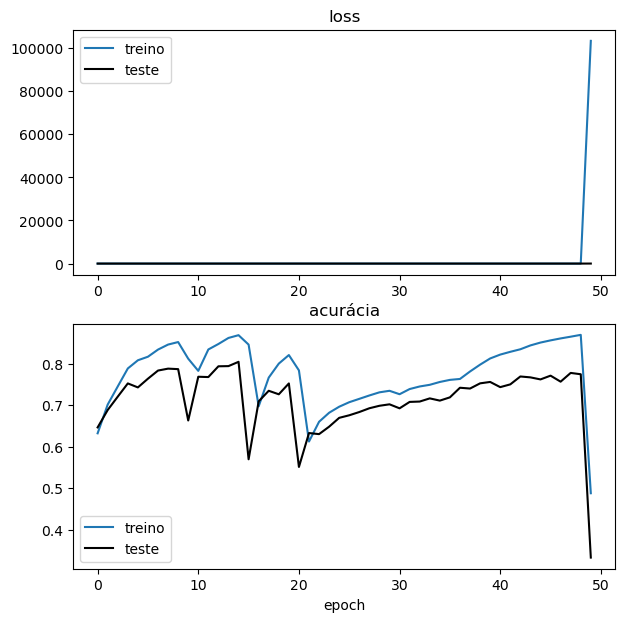

In [16]:
plt.figure(figsize= (7,7))

plt.subplot(2,1,1)
plt.title("loss")
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'], 'k')
plt.legend(['treino', 'teste'])

plt.subplot(2,1,2)
plt.title("acurácia")
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'], 'k')
plt.legend(['treino', 'teste'])
plt.xlabel('epoch')

In [17]:
accuracy = model.evaluate(testX, testY)
print('Acurácia: %.2f%%' % (accuracy[1]*100))
print('Loss: %.2f' % (accuracy[0]))


79/79 [==============================] - 1s 8ms/step - loss: 321.1675 - accuracy: 0.2549
Acurácia: 25.49%
Loss: 321.17
